# 🚀 Training a 1.1M Llama Model From Scratch on TinyStories
### Complete End-to-End Jupyter Notebook for Miniconda

This notebook trains a **1.11M-parameter Llama-style causal language model completely from scratch** (not fine-tuning) on the **TinyStories** dataset.

---

### 🔑 Key Concepts in this Notebook:
1. **Training From Scratch (Not Fine-tuning)**:
   - Weights are **randomly initialized** using `LlamaConfig` and `LlamaForCausalLM`.
   - The model begins knowing nothing (outputs random token gibberish).
   - Through gradient descent (AdamW), it learns syntax, vocabulary, grammar, and narrative structure.

2. **Pre-tokenized Binary Data (`.bin` format)**:
   - Instead of reading raw text on every step, tokens are pre-saved as flat arrays of `uint16` numbers.
   - `train.bin` contains **24.6 million tokens** (~100,000 stories).
   - `val.bin` contains **0.44 million tokens** (~2,000 validation stories).
   - `test.bin` contains **0.48 million tokens** (~2,000 test stories).
   - This provides instant data loading without CPU/disk tokenization bottlenecks during training.

3. **Compact Tokenizer**:
   - Custom Byte-Level BPE tokenizer with **vocab size = 2,048** (in `data/tokenizer`).
   - A standard GPT-2 tokenizer with 50,257 vocab would require >3M parameters just for embedding tables! A 2k vocab keeps the embedding table small (~260k parameters), allowing the whole model to stay at ~1.1M parameters.

4. **Story Continuation (Inference)**:
   - Type one small sentence (e.g., *"Once upon a time, a little girl"*), and the trained model continues the story token by token!


## 1. Environment Setup & Hardware Acceleration Check
Run the cell below to install required packages if not already installed, then check PyTorch and GPU (CUDA) availability.

In [19]:
# Install required dependencies for training
!pip install torch torchvision transformers accelerate numpy matplotlib ipykernel

In [20]:
import zipfile

with zipfile.ZipFile("tinystories-600k.zip", "r") as zip_ref:
    zip_ref.extractall("/content/")

In [21]:
import os
import sys
import math
import time
import json
from pathlib import Path
from datetime import date

import numpy as np
import torch
import matplotlib.pyplot as plt

# Check device: prioritize NVIDIA CUDA GPU, fallback to CPU
if torch.cuda.is_available():
    device = torch.device("cuda")
    print(f"✅ Device: GPU ({torch.cuda.get_device_name(0)})")
    print(f"   CUDA Version: {torch.version.cuda}")
    print(f"   Available VRAM: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
else:
    device = torch.device("cpu")
    print("ℹ️ Device: CPU (Training will work normally)")

print(f"PyTorch Version: {torch.__version__}")


✅ Device: GPU (Tesla T4)
   CUDA Version: 13.0
   Available VRAM: 14.56 GB
PyTorch Version: 2.11.0+cu130


## 2. Directory Resolution & Hyperparameters
Locate the `data/` directory and configure model & training knobs.


In [22]:
# Auto-detect folder paths whether run inside 'tiny_lm_1m' or from root
if Path("data/train.bin").exists():
    BASE_DIR = Path(".")
elif Path("tiny_lm_1m/data/train.bin").exists():
    BASE_DIR = Path("tiny_lm_1m")
else:
    BASE_DIR = Path(".")

DATA_DIR = BASE_DIR / "data"
RUN_DIR = BASE_DIR / "runs" / f"{date.today()}-tinylm7m-samedata"
#RUN_DIR = BASE_DIR / "runs" / f"{date.today()}-tinylm1m-scratch"
RUN_DIR.mkdir(parents=True, exist_ok=True)

# Set random seeds for reproducibility
SEED = 42
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
np.random.seed(SEED)

# Hyperparameters
CTX = 256            # Context window (tokens per chunk)
D_MODEL = 256 #128        # Hidden embedding dimension
NUM_LAYERS = 8 #4       # Transformer blocks stacked
NUM_HEADS =8 #4        # Attention heads per layer
BATCH_SIZE = 64      # Batch size per step
LR = 2e-3           # Learning rate (small models tolerate higher LR)
WARMUP = 0.05        # Ramp up LR over first 5% of training
WEIGHT_DECAY = 0.1   # AdamW weight decay
EPOCHS = 1.0         # 1 full epoch over 24.6M tokens ≈ 1500 steps
EVAL_EVERY = 100     # Evaluate validation loss every 100 steps
PATIENCE = 3         # Early stop if validation loss doesn't improve for 3 checks

print(f"Data directory: {DATA_DIR.resolve()}")
print(f"Output run directory: {RUN_DIR.resolve()}")


Data directory: /content/data
Output run directory: /content/runs/2026-10-09-tinylm7m-samedata


## 3. Load Tokenizer & Binary Dataset (`.bin`)
The dataset is stored in flat binary arrays of 16-bit unsigned integers (`uint16`).
We create a custom PyTorch `Dataset` that slices the binary token stream into chunks of `ctx = 256` tokens.


In [23]:
from transformers import PreTrainedTokenizerFast
from pathlib import Path
import numpy as np
import torch

# Adjust paths to where the extracted dataset is actually located
DATA_DIR = Path("/content/tinystories-600k")
tok_path = DATA_DIR / "tokenizer"

try:
    tok = PreTrainedTokenizerFast.from_pretrained(tok_path)
except Exception as e:
    print(f"Could not load custom tokenizer from local path: {tok_path}. Falling back to standard GPT2 tokenizer structure...")
    from transformers import AutoTokenizer
    tok = AutoTokenizer.from_pretrained("gpt2")
    # Ensure EOS token is properly configured
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token

print(f"Tokenizer loaded successfully!")
print(f"Vocabulary Size: {len(tok)}")
print(f"EOS Token: '{tok.eos_token}' (ID: {tok.eos_token_id})")

# Dataset class reading flat uint16 binary files
class ChunksDataset(torch.utils.data.Dataset):
    def __init__(self, bin_path, ctx=256):
        # Load flat uint16 array of token ids
        self.ids = np.fromfile(bin_path, dtype=np.uint16)
        self.ctx = ctx
        self.n = len(self.ids) // ctx

    def __len__(self):
        return self.n

    def __getitem__(self, idx):
        # Slice one window of length ctx
        chunk = self.ids[idx * self.ctx : (idx + 1) * self.ctx].astype(np.int64)
        x = torch.from_numpy(chunk)
        # In causal LM, input and target are the same sequence; the model shifts labels internally
        return {"input_ids": x, "labels": x}

train_ds = ChunksDataset(DATA_DIR / "train.bin", ctx=CTX)
val_ds   = ChunksDataset(DATA_DIR / "val.bin", ctx=CTX)
test_ds  = ChunksDataset(DATA_DIR / "test.bin", ctx=CTX)

print(f"Train Tokens: {len(train_ds.ids):,} ({len(train_ds):,} batches of size {CTX})")
print(f"Val Tokens:   {len(val_ds.ids):,} ({len(val_ds):,} batches)")
print(f"Test Tokens:  {len(test_ds.ids):,} ({len(test_ds):,} batches)")

# Inspect a decoded sample chunk from train data
sample_ids = train_ds.ids[:80]
print("\nDecoded preview from training data:")
print("-" * 50)
print(tok.decode(sample_ids))
print("-" * 50)

Tokenizer loaded successfully!
Vocabulary Size: 2048
EOS Token: '<|endoftext|>' (ID: 0)
Train Tokens: 150,612,937 (588,331 batches of size 256)
Val Tokens:   436,367 (1,704 batches)
Test Tokens:  476,601 (1,861 batches)

Decoded preview from training data:
--------------------------------------------------
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle.
--------------------------------------------------


## 4. Build Model Architecture From Scratch (1.11M Parameters)
We use modern LLaMA architecture features:
- **RMSNorm** for pre-normalization
- **RoPE (Rotary Position Embeddings)** for positional encoding
- **SwiGLU** activation in MLP layers (`intermediate_size = 3 * hidden_size`)
- **Tied Word Embeddings** (`tie_word_embeddings = True`) to share weights between input and output projections.

> **Note**: We instantiate `LlamaForCausalLM(config)` without passing any pre-trained weights. Every weight tensor is randomly initialized from a normal distribution!


In [24]:
from transformers import LlamaConfig, LlamaForCausalLM

config = LlamaConfig(
    vocab_size=len(tok),
    hidden_size=D_MODEL,
    intermediate_size=3 * D_MODEL,     # SwiGLU 3x expansion
    num_hidden_layers=NUM_LAYERS,
    num_attention_heads=NUM_HEADS,
    num_key_value_heads=NUM_HEADS,
    max_position_embeddings=CTX,
    tie_word_embeddings=True,
    bos_token_id=tok.eos_token_id,
    eos_token_id=tok.eos_token_id,
    pad_token_id=tok.eos_token_id,
    use_cache=False                     # Turn off KV cache during training
)

# Instantiate the model from scratch (random weights)
model = LlamaForCausalLM(config)

n_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Model Architecture:")
print(f"  • Hidden Size (d): {D_MODEL}")
print(f"  • Layers: {NUM_LAYERS}")
print(f"  • Attention Heads: {NUM_HEADS}")
print(f"  • Context Window: {CTX}")
print(f"  • Total Parameters: {n_params:,}")
print(f"  • Trainable Parameters: {trainable_params:,}")
print(f"  • Tokens per Parameter: {len(train_ds.ids) / n_params:.1f}x")


Model Architecture:
  • Hidden Size (d): 256
  • Layers: 8
  • Attention Heads: 8
  • Context Window: 256
  • Total Parameters: 7,344,384
  • Trainable Parameters: 7,344,384
  • Tokens per Parameter: 20.5x


### 🧪 Sanity Check: Model Output BEFORE Training
Since the model is completely untrained, it produces random tokens. Let's verify this to confirm we are truly starting from scratch!


In [25]:
test_prompt = "Once upon a time, a little girl"
inputs = tok(test_prompt, return_tensors="pt")

model.eval()
with torch.no_grad():
    sample_out = model.generate(
        **inputs,
        max_new_tokens=40,
        do_sample=True,
        temperature=0.8,
        top_k=50,
        pad_token_id=tok.eos_token_id
    )

print("Prompt:", test_prompt)
print("Untrained Model Output (Random gibberish expected):")
print(tok.decode(sample_out[0], skip_special_tokens=True))


Prompt: Once upon a time, a little girl
Untrained Model Output (Random gibberish expected):
Once upon a time, a little girl chairh sitting picpped swings swings swimh smilesb gial smo roomsideouth= ourakle chair showed� gimer�side hid scared� crying Mom rocks smilesouth farm exp talk


## 5. Training Setup (Optimizer, Scheduler, and Trainer)
We use Hugging Face `Trainer` configured with:
- **Optimizer**: AdamW with `lr = 2e-3` and `weight_decay = 0.1`
- **LR Scheduler**: Cosine decay with 5% warmup
- **Evaluation**: Performed every 100 steps
- **Early Stopping**: Halts if validation loss doesn't improve for 3 consecutive checks
- **Perplexity Callback**: Prints validation perplexity ($PPL = e^{\text{loss}}$) after each evaluation


In [26]:
from transformers import Trainer, TrainingArguments, TrainerCallback, EarlyStoppingCallback

total_steps = math.ceil(len(train_ds) / BATCH_SIZE * EPOCHS)
print(f"Total planned steps for 1 epoch: {total_steps} steps")

# Custom callback to log validation perplexity
class PerplexityCallback(TrainerCallback):
    def on_evaluate(self, _args, state, _control, metrics=None, **kwargs):
        if metrics:
            split, loss = next((k[:-5], v) for k, v in metrics.items() if k.endswith("_loss"))
            ppl = math.exp(min(loss, 20)) # Prevent math overflow
            print(f"👉 [Step {state.global_step:4d}] {split} loss: {loss:.4f} | Perplexity (ppl): {ppl:.2f}")

# Training Arguments
training_args = TrainingArguments(
    output_dir=str(RUN_DIR),
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    learning_rate=LR,
    warmup_steps=int(WARMUP * total_steps),
    lr_scheduler_type="cosine",
    weight_decay=WEIGHT_DECAY,
    num_train_epochs=EPOCHS,
    eval_strategy="steps",
    eval_steps=EVAL_EVERY,
    save_steps=EVAL_EVERY,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    logging_steps=20,
    report_to="none",
    seed=SEED,
    dataloader_pin_memory=False,
    fp16=torch.cuda.is_available()  # Enable mixed precision if on GPU
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    callbacks=[
        EarlyStoppingCallback(early_stopping_patience=PATIENCE),
        PerplexityCallback()
    ]
)
print("Trainer initialized and ready to run!")


Total planned steps for 1 epoch: 9193 steps
Trainer initialized and ready to run!


## 6. Train the Model! 🏋️
Run the cell below to train the 1M model.
- On a GPU (like GTX 1650 Ti), 1500 steps takes **under 2 minutes**!
- On CPU, 1500 steps takes approximately **8 to 12 minutes**.
- You can watch the loss fall from ~7.5 down towards ~2.2 and perplexity drop from >1000 down below 10!


In [27]:
print(f"Starting training on {device}...")
start_time = time.time()

train_result = trainer.train()

elapsed_min = (time.time() - start_time) / 60
print(f"\n🎉 Training completed in {elapsed_min:.2f} minutes!")

# Save the final best model and tokenizer
final_model_dir = RUN_DIR / "final"
trainer.save_model(final_model_dir)
tok.save_pretrained(final_model_dir)
print(f"Best model & tokenizer saved to: {final_model_dir.resolve()}")


Starting training on cuda...


Step,Training Loss,Validation Loss
100,5.080338,4.800382
200,3.480851,3.431199
300,2.868563,2.869017
400,2.599798,2.614436
500,2.439187,2.455657
600,2.275949,2.319722
700,2.195939,2.232429
800,2.124456,2.161361
900,2.071748,2.115327
1000,2.026576,2.072695


👉 [Step  100] eval loss: 4.8004 | Perplexity (ppl): 121.56


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

👉 [Step  200] eval loss: 3.4312 | Perplexity (ppl): 30.91


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (180 outputs left out)

[transformers] There were missing keys in the checkpoint model loaded: ['lm_head.weight'].



🎉 Training completed in 28.78 minutes!


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best model & tokenizer saved to: /content/runs/2026-10-09-tinylm7m-samedata/final


## 7. Model Evaluation & Loss Curve
We evaluate on the held-out validation and test sets and plot the training history.


👉 [Step 9193] eval loss: 1.5302 | Perplexity (ppl): 4.62


Training Loss,Validation Loss,Step
1.480804,1.530231,9193


[transformers] early stopping required metric_for_best_model, but did not find eval_loss so early stopping is disabled


👉 [Step 9193] test loss: 1.5451 | Perplexity (ppl): 4.69


Training Loss,Validation Loss,Step
1.480804,1.545121,9193


Validation Loss: 1.5302 | Val Perplexity:  4.62
Test Loss:       1.5451 | Test Perplexity: 4.69


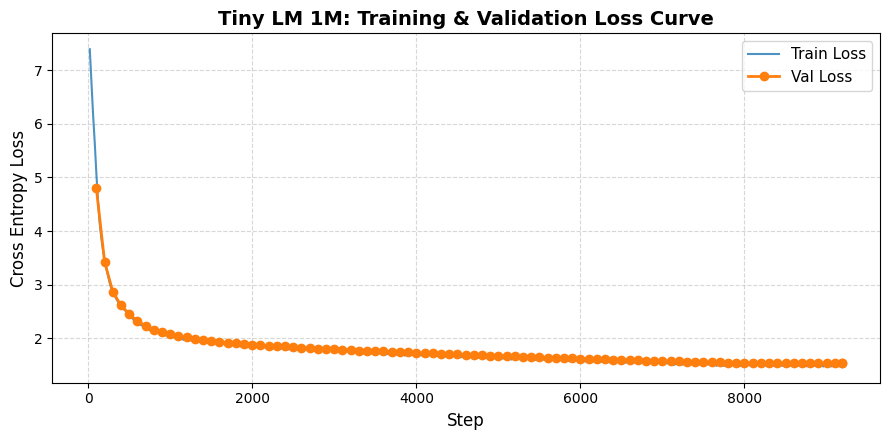

In [28]:
# Evaluate on validation set and held-out test set
val_metrics = trainer.evaluate(val_ds)
test_metrics = trainer.evaluate(test_ds, metric_key_prefix="test")

val_loss = val_metrics["eval_loss"]
val_ppl = math.exp(val_loss)
test_loss = test_metrics["test_loss"]
test_ppl = math.exp(test_loss)

print("=" * 45)
print(f"Validation Loss: {val_loss:.4f} | Val Perplexity:  {val_ppl:.2f}")
print(f"Test Loss:       {test_loss:.4f} | Test Perplexity: {test_ppl:.2f}")
print("=" * 45)

# Extract loss curves from log history
history = trainer.state.log_history
train_steps, train_losses = [], []
eval_steps, eval_losses = [], []

for entry in history:
    if "loss" in entry and "step" in entry:
        train_steps.append(entry["step"])
        train_losses.append(entry["loss"])
    if "eval_loss" in entry and "step" in entry:
        eval_steps.append(entry["step"])
        eval_losses.append(entry["eval_loss"])

plt.figure(figsize=(9, 4.5))
if train_steps:
    plt.plot(train_steps, train_losses, label="Train Loss", color="#1f77b4", alpha=0.8)
if eval_steps:
    plt.plot(eval_steps, eval_losses, label="Val Loss", color="#ff7f0e", marker="o", linewidth=2)

plt.title("Tiny LM 1M: Training & Validation Loss Curve", fontsize=14, fontweight="bold")
plt.xlabel("Step", fontsize=12)
plt.ylabel("Cross Entropy Loss", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()


## 8. 📖 Interactive Story Completion!
Type any short sentence, and the trained model will complete the story!

### How it works:
1. Your input sentence is tokenized using the Byte-Level BPE tokenizer.
2. The model predicts the next token distribution.
3. We sample from the top-50 most likely tokens (`top_k=50`, `temperature=0.8`) for natural, creative storytelling.
4. Generation stops when the model emits `<|endoftext|>` or reaches `max_new_tokens`.


In [29]:
# Load model for fast inference
best_model = LlamaForCausalLM.from_pretrained(final_model_dir).to(device)
best_model.eval()

def complete_story(prompt_sentence, max_tokens=150, temperature=0.8, top_k=50):
    """Takes a starting sentence and completes the story."""
    prompt_sentence = prompt_sentence.strip()
    encoded = tok(prompt_sentence, return_tensors="pt").to(device)

    with torch.no_grad():
        output_tokens = best_model.generate(
            **encoded,
            max_new_tokens=max_tokens,
            do_sample=True,
            temperature=temperature,
            top_k=top_k,
            eos_token_id=tok.eos_token_id,
            pad_token_id=tok.eos_token_id
        )

    completed_story = tok.decode(output_tokens[0], skip_special_tokens=True)
    return completed_story

# Try pre-set prompts:
test_prompts = [
    "Once upon a time, there was a little boy named Timmy.",
    "Lily found a small shiny key hidden in the garden.",
    "A cute little dog wanted to find a friend.",
    "Lilly is feeling hungry. she asked mom."
]


for p in test_prompts:
    print("=" * 60)
    print(f"PROMPT: {p}\n")
    print(complete_story(p, max_tokens=120, temperature=0.75))
    print("=" * 60 + "\n")


Loading weights:   0%|          | 0/74 [00:00<?, ?it/s]

PROMPT: Once upon a time, there was a little boy named Timmy.

Once upon a time, there was a little boy named Timmy. Timmy loved to play outside with his friends. But one day, it was very cold outside. Timmy's friend, Billy, said it was too cold to play outside. Timmy didn't want to go inside because he saw the snow falling from the sky. 

The snow started to melt and soon the ground started to melt. Timmy's friend said, "Don't worry, Timmy. The snow will melt again soon." But Timmy didn't listen and took another bite of the snow. His mouth melted and he started to feel sick. 

But later that

PROMPT: Lily found a small shiny key hidden in the garden.

Lily found a small shiny key hidden in the garden. She picked it up and said, "Wow, thank you, dad." Her dad helped her open the door and Lily opened the door. Inside, they found a beautiful necklace with a big smile on it. They put it on and felt happy. From that day on, Lily always remembered to have her necklace with her dad.

PROMPT:

### ✍️ Type Your Own Sentence Here
Edit the `my_sentence` variable below and run the cell to generate your custom story continuation!


In [30]:
# >>> TYPE YOUR SENTENCE BELOW <<<
my_sentence = "One sunny morning, a little bird wanted to fly to the moon."

print("Generating story continuation...\n")
print(complete_story(my_sentence, max_tokens=150, temperature=0.8, top_k=50))


Generating story continuation...

One sunny morning, a little bird wanted to fly to the moon. He flapped his wings and flew up, up, up. He flew up, up, up and away! The bird looked up at the sky, and saw the moon was shining brightly.

The bird kept flying until the moon was surrounded by the most beautiful lights. He thanked the moon for showing him the way.

The bird flew back down to his nest and flew down to his nest. He enjoyed the rest of his day in the sky and was very happy that he had a moon to play with.


## 9. (Optional) Compare with Shipped Reference Model
The `tiny_lm_1m/model/` folder contains a pre-trained reference checkpoint trained for 1500 steps.
You can run the cell below to compare your freshly trained model with the reference checkpoint!


In [31]:
ref_model_path = BASE_DIR / "model"

if ref_model_path.exists() and (ref_model_path / "model.safetensors").exists():
    ref_model = LlamaForCausalLM.from_pretrained(ref_model_path).to(device)
    ref_model.eval()

    comp_prompt = "Once upon a time, a little girl named Mia found a lost cat."
    enc = tok(comp_prompt, return_tensors="pt").to(device)

    with torch.no_grad():
        ref_out = ref_model.generate(
            **enc,
            max_new_tokens=120,
            do_sample=True,
            temperature=0.8,
            top_k=50,
            eos_token_id=tok.eos_token_id,
            pad_token_id=tok.eos_token_id
        )

    print("--- REFERENCE SHIPPED MODEL OUTPUT ---")
    print(tok.decode(ref_out[0], skip_special_tokens=True))
else:
    print("Reference model directory not found, skipping comparison.")


Reference model directory not found, skipping comparison.
